In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np



In [4]:
df = pd.read_csv(
    "/content/drive/MyDrive/cryptocast/data/bitcoin.csv"
)

In [5]:
df.head()

,Date,Price,Open,High,Low,Vol.,Change %
0,24-03-2024,"67,211.90","64,036.50","67,587.80","63,812.90",65.59K,4.96%
1,23-03-2024,"64,037.80","63,785.60","65,972.40","63,074.90",35.11K,0.40%
2,22-03-2024,"63,785.50","65,501.50","66,633.30","62,328.30",72.43K,-2.62%
3,21-03-2024,"65,503.80","67,860.00","68,161.70","64,616.10",75.26K,-3.46%
4,20-03-2024,"67,854.00","62,046.80","68,029.50","60,850.90",133.53K,9.35%


In [6]:
df.shape

(4999, 7)

In [7]:
df.columns

Index(['Date', 'Price', 'Open', 'High', 'Low', 'Vol.', 'Change %'], dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      4999 non-null   object
 1   Price     4999 non-null   object
 2   Open      4999 non-null   object
 3   High      4999 non-null   object
 4   Low       4999 non-null   object
 5   Vol.      4993 non-null   object
 6   Change %  4999 non-null   object
dtypes: object(7)
memory usage: 273.5+ KB


In [9]:
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

In [10]:
df['Date'].dtype

dtype('<M8[ns]')

In [11]:
df['Date'].isnull().sum()

np.int64(0)

In [12]:
df['Date'].duplicated().sum()

np.int64(0)

In [13]:
df = df.sort_values('Date').reset_index(drop=True)

In [14]:
print("Start Date:", df['Date'].min())
print("End Date:", df['Date'].max())

Start Date: 2010-07-18 00:00:00
End Date: 2024-03-24 00:00:00


In [15]:
df['Price'].dtype

dtype('O')

In [16]:
df['Price'] = df['Price'].str.replace(',', '', regex=False)
df['Price'] = df['Price'].astype(float)

In [17]:
df['Price'].isnull().sum()

np.int64(0)

In [18]:
df['Price'].duplicated().sum()

np.int64(955)

In [19]:
df['Price'].dtype

dtype('float64')

In [20]:
df['Price'].shape

(4999,)

In [21]:
df['Price'].describe()

,Price
count,4999.000000
mean,10812.283337
std,15892.032468
min,0.100000
25%,226.700000
50%,1975.100000
75%,15450.150000
max,73066.300000


In [22]:
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Price'] < lower_bound) |
    (df['Price'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(outliers))

Q1: 226.7
Q3: 15450.150000000001
IQR: 15223.45
Lower Bound: -22608.475000000002
Upper Bound: 38285.325000000004
Number of Outliers: 492


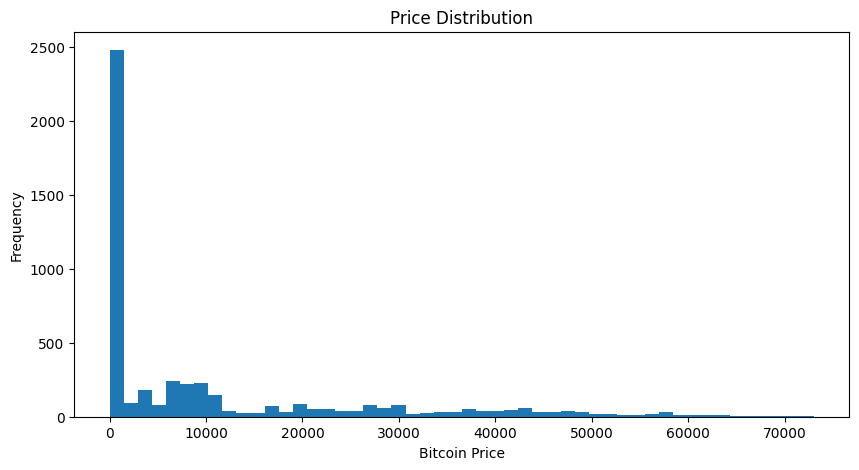

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df['Price'].dropna(), bins=50)

plt.title('Price Distribution')
plt.xlabel('Bitcoin Price')
plt.ylabel('Frequency')

plt.show()

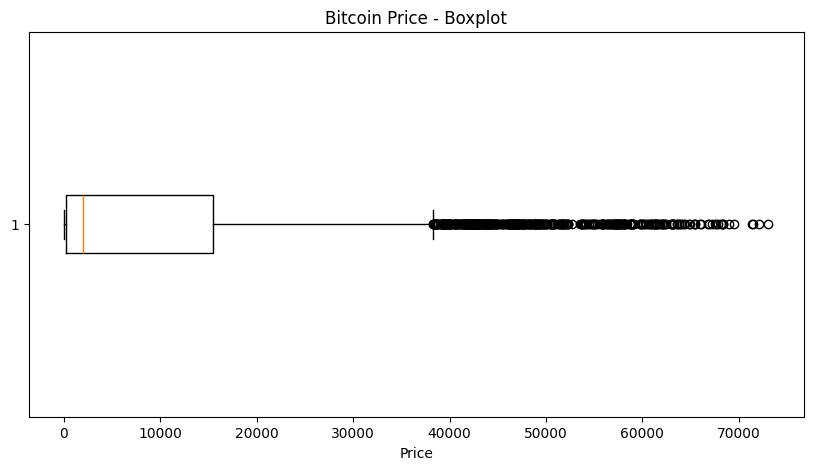

In [24]:
plt.figure(figsize=(10, 5))
plt.boxplot(df['Price'], vert=False)

plt.title('Bitcoin Price - Boxplot')
plt.xlabel('Price')

plt.show()

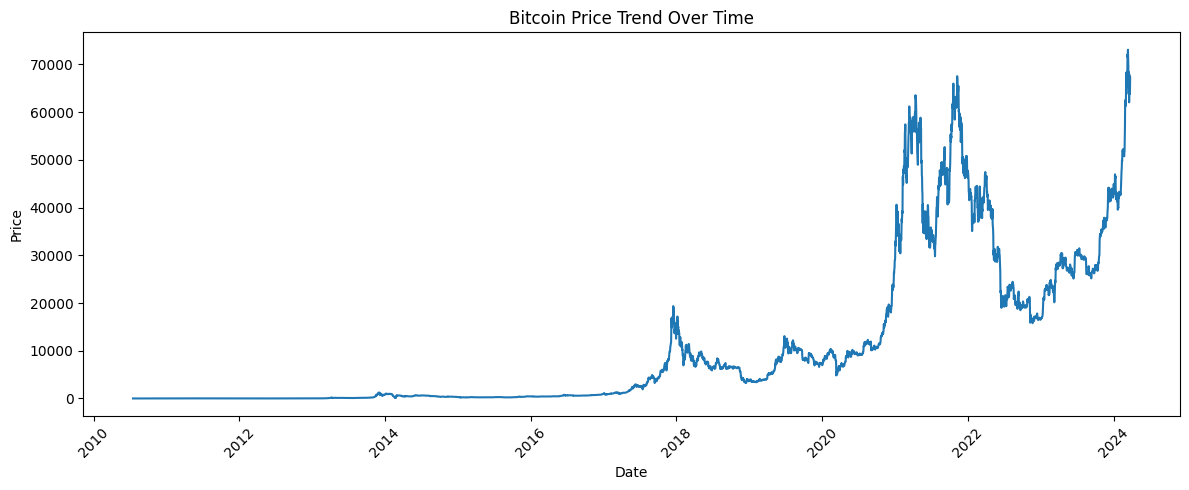

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(df['Date'], df['Price'])

plt.title('Bitcoin Price Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Price')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [26]:
df['Open'].head()

,Open
0,0
1,0.1
2,0.1
3,0.1
4,0.1


In [27]:
df['Open'].dtype

dtype('O')

In [28]:
df['Open'] = df['Open'].str.replace(',', '', regex=False)
df['Open'] = df['Open'].astype(float)

In [29]:
df['Open'].isnull().sum()

np.int64(0)

In [30]:
df['Open'].dtype

dtype('float64')

In [31]:
df['Open'].duplicated().sum()

np.int64(962)

In [32]:
df['Open'].shape

(4999,)

In [33]:
df['Open'].describe()

,Open
count,4999.000000
mean,10798.901840
std,15872.785452
min,0.000000
25%,226.450000
50%,1962.000000
75%,15372.150000
max,73066.700000


In [34]:
Q1 = df['Open'].quantile(0.25)
Q3 = df['Open'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

open_outliers = df[
    (df['Open'] < lower_bound) |
    (df['Open'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(open_outliers))

Q1: 226.45
Q3: 15372.15
IQR: 15145.699999999999
Lower Bound: -22492.1
Upper Bound: 38090.7
Number of Outliers: 496


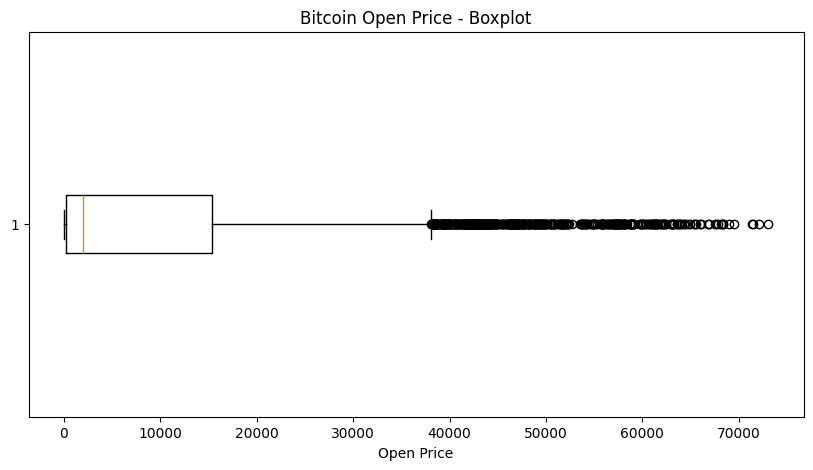

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.boxplot(df['Open'].dropna(), vert=False)

plt.title('Bitcoin Open Price - Boxplot')
plt.xlabel('Open Price')

plt.show()

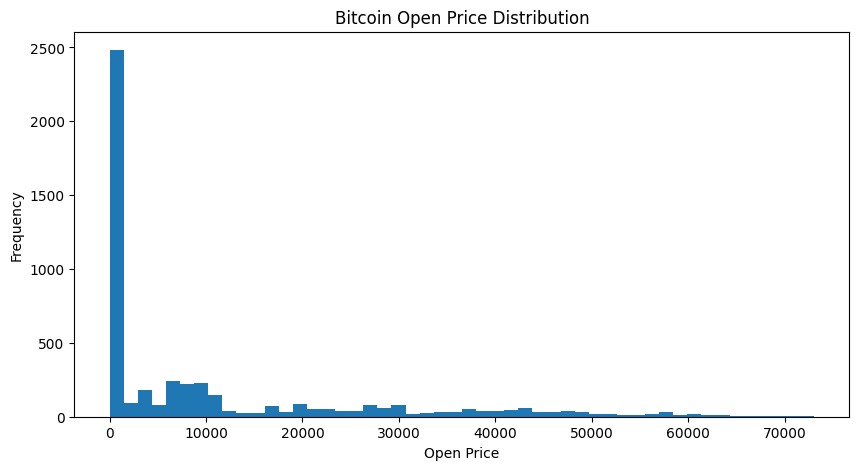

In [36]:
plt.figure(figsize=(10, 5))

plt.hist(df['Open'].dropna(), bins=50)

plt.title('Bitcoin Open Price Distribution')
plt.xlabel('Open Price')
plt.ylabel('Frequency')

plt.show()

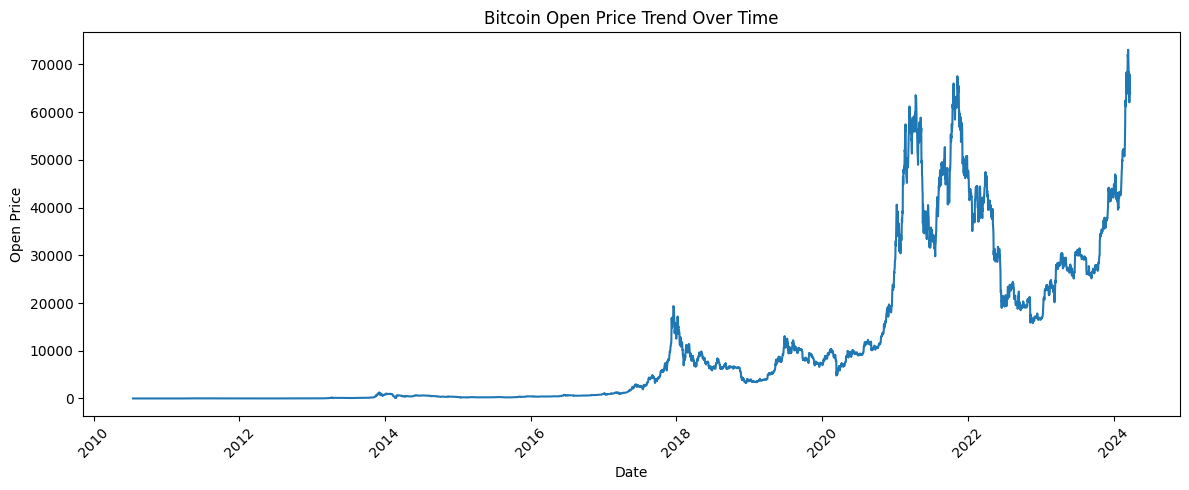

In [37]:
plt.figure(figsize=(12, 5))

plt.plot(df['Date'], df['Open'])

plt.title('Bitcoin Open Price Trend Over Time')
plt.xlabel('Date')
plt.ylabel('Open Price')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [38]:
df['High'].head()

,High
0,0.1
1,0.1
2,0.1
3,0.1
4,0.1


In [39]:
df['High'].isnull().sum()

np.int64(0)

In [40]:
df['High'] = df['High'].str.replace(',', '', regex=False)
df['High'] = df['High'].astype(float)

In [41]:
df['High'].duplicated().sum()

np.int64(967)

In [42]:
df['High'].describe()

,High
count,4999.000000
mean,11067.453051
std,16270.707594
min,0.100000
25%,231.400000
50%,2048.400000
75%,15954.550000
max,73740.900000


In [43]:
Q1 = df['High'].quantile(0.25)
Q3 = df['High'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

high_outliers = df[
    (df['High'] < lower_bound) |
    (df['High'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(high_outliers))

Q1: 231.4
Q3: 15954.55
IQR: 15723.15
Lower Bound: -23353.324999999997
Upper Bound: 39539.274999999994
Number of Outliers: 489


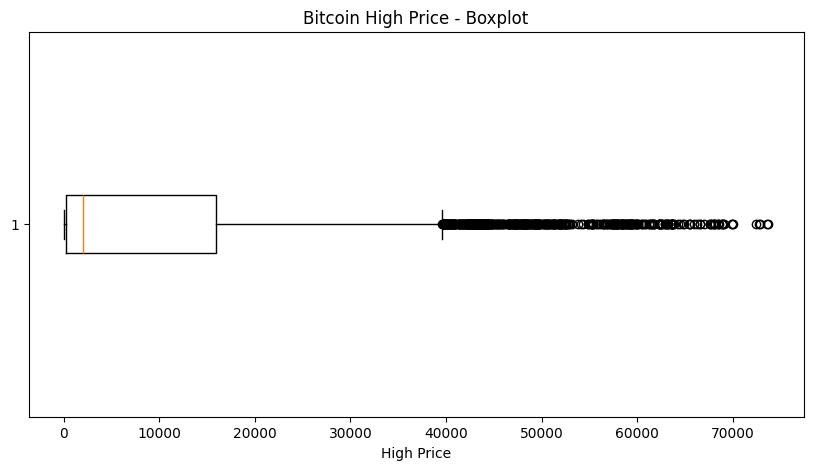

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.boxplot(df['High'].dropna(), vert=False)
plt.title('Bitcoin High Price - Boxplot')
plt.xlabel('High Price')
plt.show()

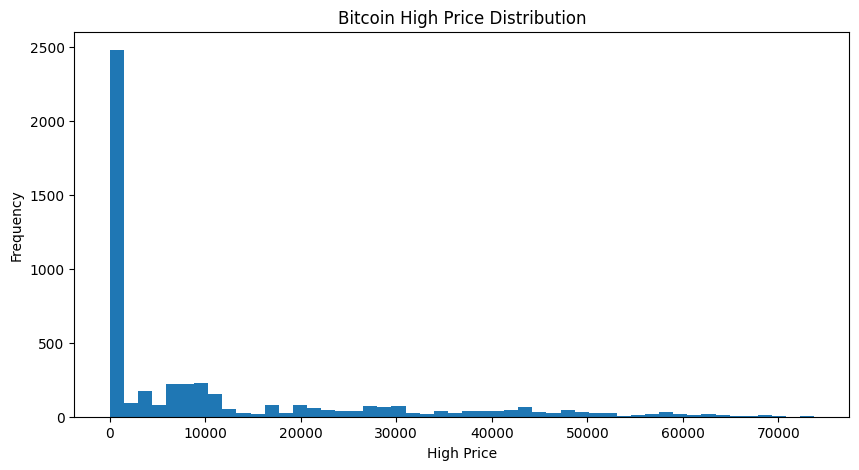

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df['High'].dropna(), bins=50)
plt.title('Bitcoin High Price Distribution')
plt.xlabel('High Price')
plt.ylabel('Frequency')
plt.show()

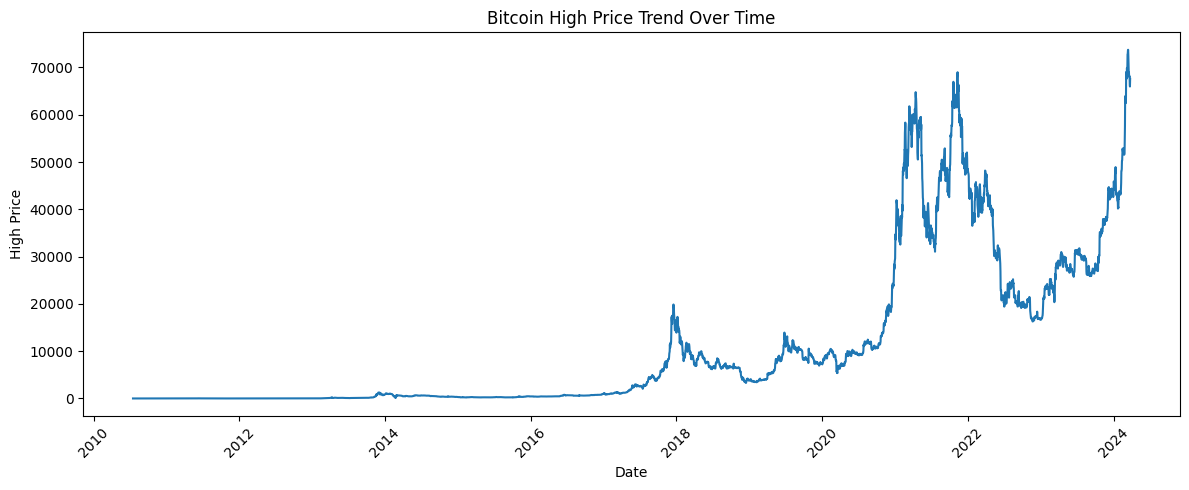

In [46]:
plt.figure(figsize=(12, 5))

plt.plot(df['Date'], df['High'])

plt.title('Bitcoin High Price Trend Over Time')
plt.xlabel('Date')
plt.ylabel('High Price')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [47]:
df['Low'] = (
    df['Low']
    .astype(str)
    .str.replace(',', '', regex=False)
)

df['Low'] = df['Low'].astype(float)

print("Data type:", df['Low'].dtype)
print("Missing values:", df['Low'].isnull().sum())

Data type: float64
Missing values: 0


In [48]:
df['Low'].duplicated().sum()

np.int64(958)

In [49]:
df['Low'].shape

(4999,)

In [50]:
df['Low'].describe()

,Low
count,4999.000000
mean,10511.891198
std,15444.928771
min,0.000000
25%,221.950000
50%,1875.300000
75%,14557.200000
max,71338.400000


In [51]:
Q1 = df['Low'].quantile(0.25)
Q3 = df['Low'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

low_outliers = df[
    (df['Low'] < lower_bound) |
    (df['Low'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(low_outliers))

Q1: 221.95
Q3: 14557.2
IQR: 14335.25
Lower Bound: -21280.925
Upper Bound: 36060.075
Number of Outliers: 522


In [52]:
print("Missing values:", df['Low'].isnull().sum())

Missing values: 0


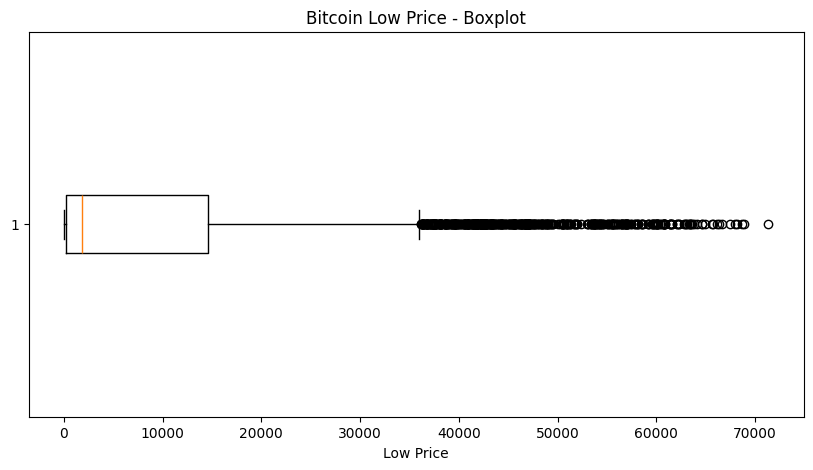

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.boxplot(df['Low'].dropna(), vert=False)
plt.title('Bitcoin Low Price - Boxplot')
plt.xlabel('Low Price')
plt.show()

In [54]:
def convert_volume(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip().upper()

    if value.endswith('K'):
        return float(value[:-1]) * 1_000
    elif value.endswith('M'):
        return float(value[:-1]) * 1_000_000
    elif value.endswith('B'):
        return float(value[:-1]) * 1_000_000_000
    else:
        return float(value)

df['Vol.'] = df['Vol.'].apply(convert_volume)

print("Missing values:", df['Vol.'].isnull().sum())

Missing values: 6


In [55]:
df[df['Vol.'].isnull()][['Date', 'Vol.']]

,Date,Vol.
337,2011-06-20,NaN
338,2011-06-21,NaN
339,2011-06-22,NaN
340,2011-06-23,NaN
341,2011-06-24,NaN
342,2011-06-25,NaN


In [56]:
df.loc[334:345, ['Date', 'Vol.']]

,Date,Vol.
334,2011-06-17,108620.0
335,2011-06-18,35540.0
336,2011-06-19,30180.0
337,2011-06-20,NaN
338,2011-06-21,NaN
339,2011-06-22,NaN
340,2011-06-23,NaN
341,2011-06-24,NaN
342,2011-06-25,NaN
343,2011-06-26,15050.0


In [57]:
df['Vol.'] = df['Vol.'].ffill()

In [58]:
print("Missing values after filling:", df['Vol.'].isnull().sum())

Missing values after filling: 0


In [59]:
df['Vol.'].duplicated().sum()

np.int64(576)

In [60]:
Q1 = df['Vol.'].quantile(0.25)
Q3 = df['Vol.'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

volume_outliers = df[
    (df['Vol.'] < lower_bound) |
    (df['Vol.'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(volume_outliers))

Q1: 31710.0
Q3: 185065.0
IQR: 153355.0
Lower Bound: -198322.5
Upper Bound: 415097.5
Number of Outliers: 766


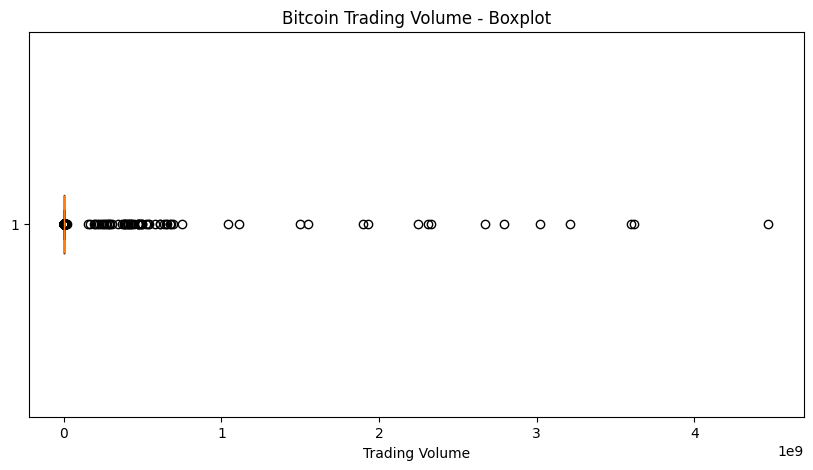

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.boxplot(df['Vol.'].dropna(), vert=False)

plt.title('Bitcoin Trading Volume - Boxplot')
plt.xlabel('Trading Volume')

plt.show()

In [62]:
print("Data type:", df['Change %'].dtype)
print("Missing values:", df['Change %'].isnull().sum())

Data type: object
Missing values: 0


In [63]:
print("Duplicate Change % values:", df['Change %'].duplicated().sum())

Duplicate Change % values: 3449


In [64]:
df['Change %'].dtype

dtype('O')

In [65]:
df['Change %'] = (
    df['Change %']
    .astype(str)
    .str.replace('%', '', regex=False)
    .str.replace(',', '', regex=False)
)

df['Change %'] = df['Change %'].astype(float)

print("Data type:", df['Change %'].dtype)
print("Missing values:", df['Change %'].isnull().sum())

Data type: float64
Missing values: 0


In [66]:
df['Change %'].tail()

,Change %
4994,9.35
4995,-3.46
4996,-2.62
4997,0.40
4998,4.96


In [67]:
df['Change %'].describe()

,Change %
count,4999.000000
mean,0.415751
std,7.094771
min,-57.210000
25%,-1.170000
50%,0.000000
75%,1.785000
max,336.840000


In [68]:
df['Change %'].duplicated().sum()

np.int64(3449)

In [69]:
Q1 = df['Change %'].quantile(0.25)
Q3 = df['Change %'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

change_outliers = df[
    (df['Change %'] < lower_bound) |
    (df['Change %'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Outliers:", len(change_outliers))

Q1: -1.17
Q3: 1.7850000000000001
IQR: 2.955
Lower Bound: -5.6025
Upper Bound: 6.2175
Number of Outliers: 626


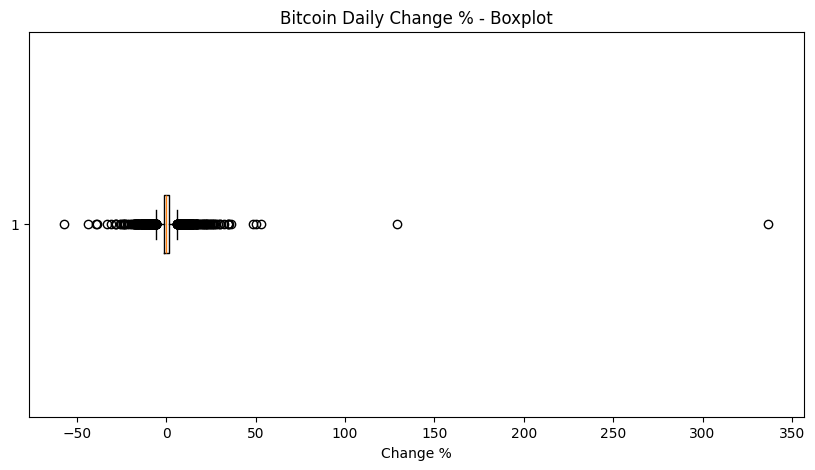

In [70]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.boxplot(df['Change %'].dropna(), vert=False)

plt.title('Bitcoin Daily Change % - Boxplot')
plt.xlabel('Change %')

plt.show()

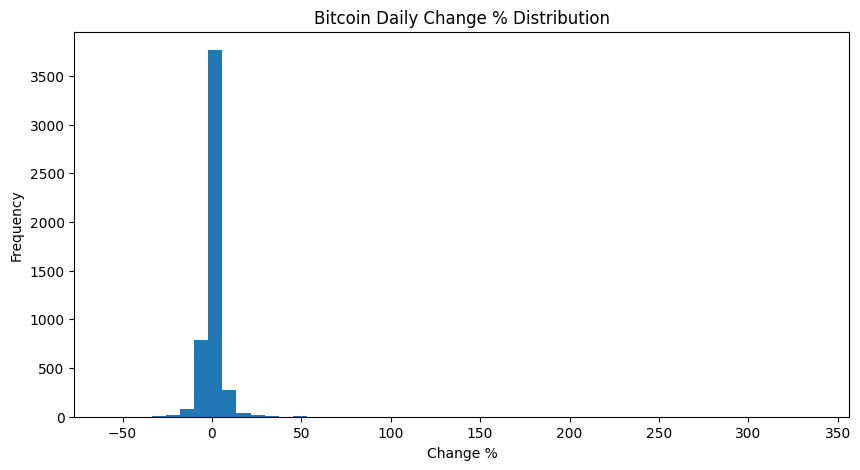

In [71]:
plt.figure(figsize=(10, 5))

plt.hist(df['Change %'].dropna(), bins=50)

plt.title('Bitcoin Daily Change % Distribution')
plt.xlabel('Change %')
plt.ylabel('Frequency')

plt.show()

In [72]:
features = ['Price', 'Open', 'High', 'Low', 'Vol.', 'Change %']

correlation = df[features].corr()

correlation

,Price,Open,High,Low,Vol.,Change %
Price,1.000000,0.999055,0.999583,0.999487,0.144869,-0.014613
Open,0.999055,1.000000,0.999577,0.999280,0.145531,-0.027925
High,0.999583,0.999577,1.000000,0.999147,0.145796,-0.020814
Low,0.999487,0.999280,0.999147,1.000000,0.145263,-0.019977
Vol.,0.144869,0.145531,0.145796,0.145263,1.000000,-0.006074
Change %,-0.014613,-0.027925,-0.020814,-0.019977,-0.006074,1.000000


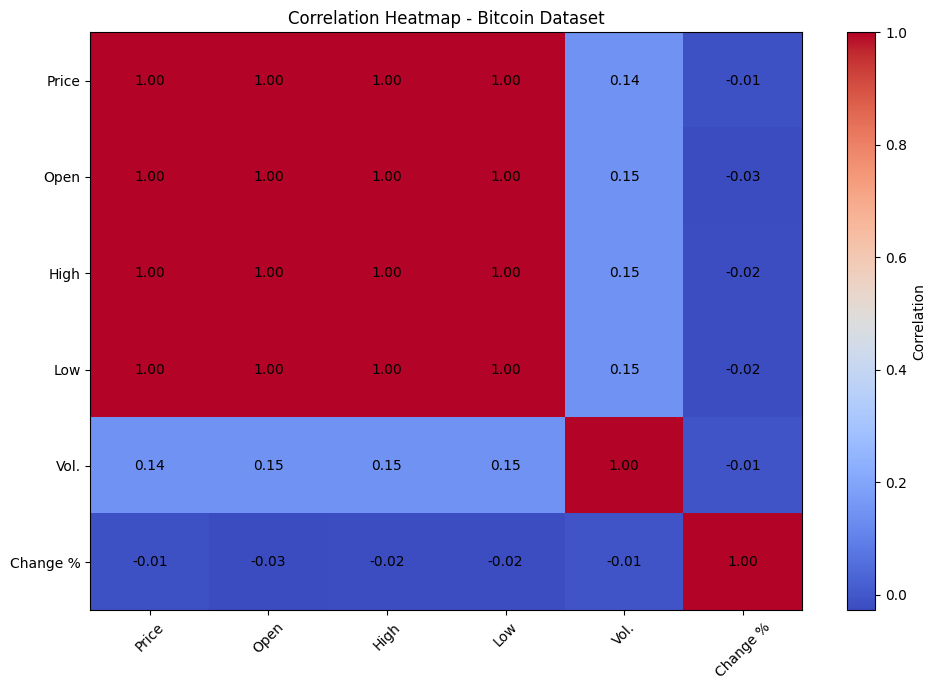

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap='coolwarm', aspect='auto')

plt.colorbar(label='Correlation')

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j, i,
            f"{correlation.iloc[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap - Bitcoin Dataset')
plt.tight_layout()
plt.show()

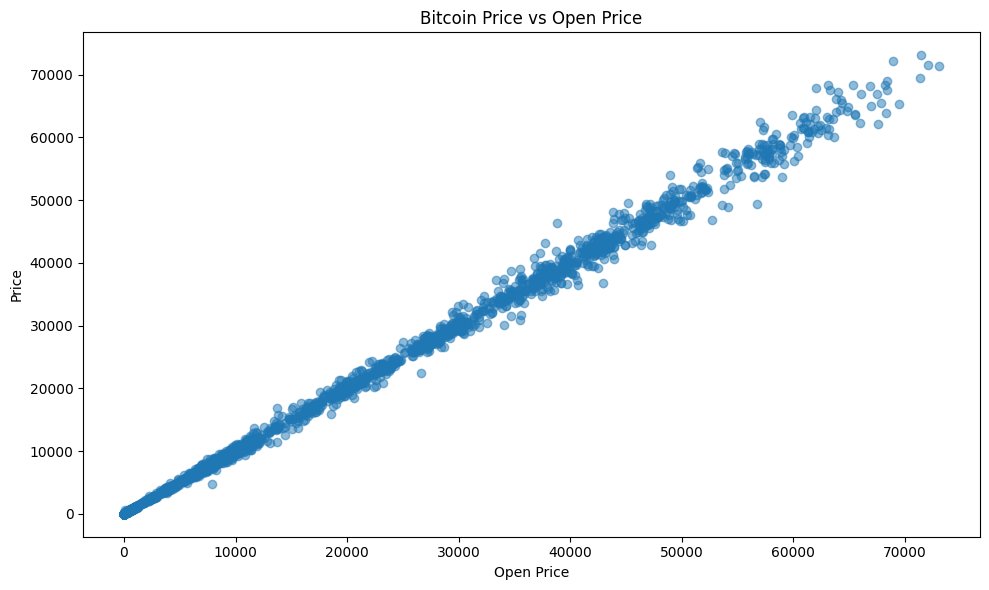

In [74]:
plt.figure(figsize=(10, 6))

plt.scatter(df['Open'], df['Price'], alpha=0.5)

plt.title('Bitcoin Price vs Open Price')
plt.xlabel('Open Price')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

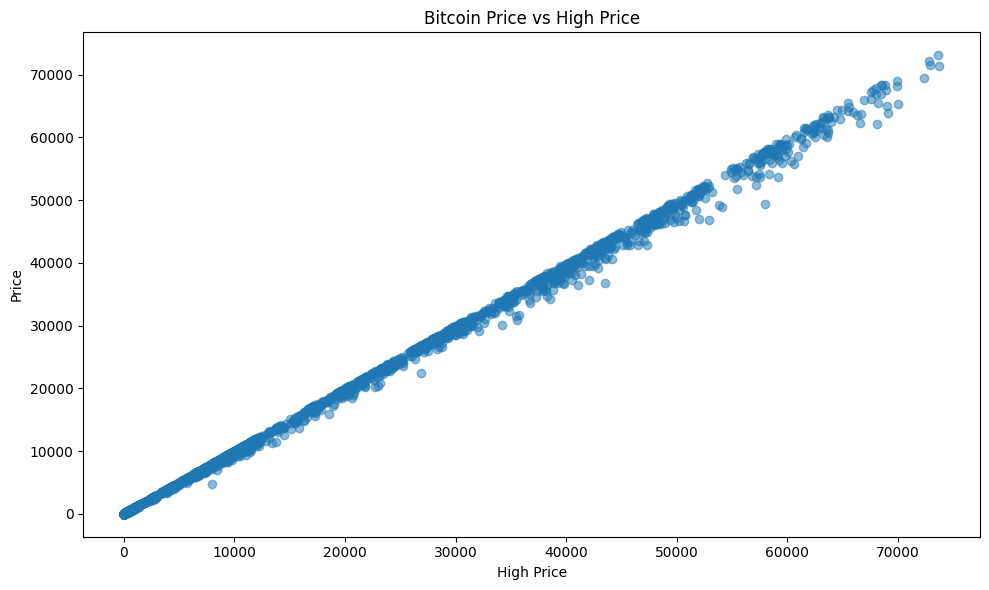

In [75]:
plt.figure(figsize=(10, 6))

plt.scatter(df['High'], df['Price'], alpha=0.5)

plt.title('Bitcoin Price vs High Price')
plt.xlabel('High Price')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

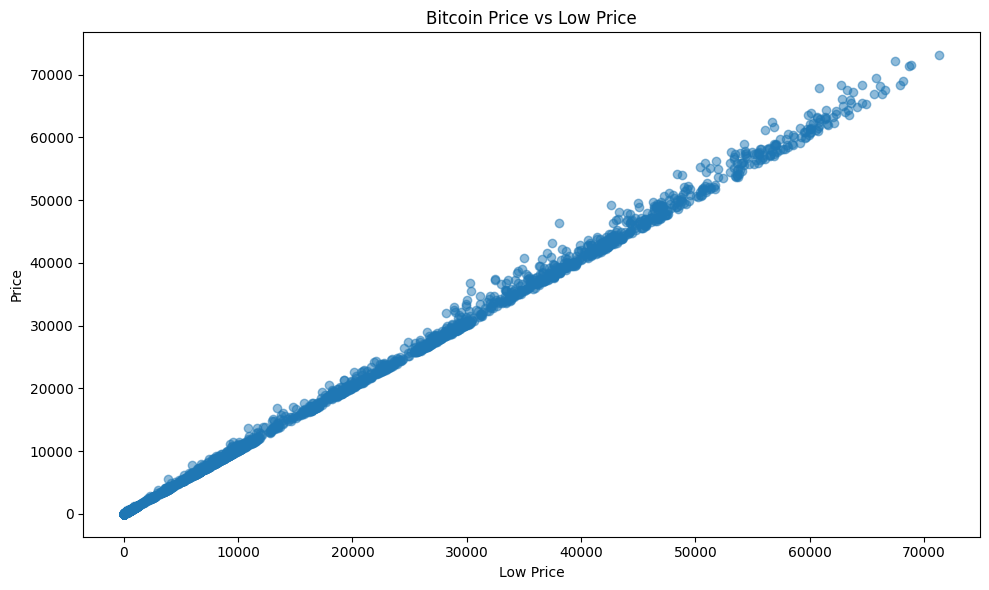

In [76]:
plt.figure(figsize=(10, 6))

plt.scatter(df['Low'], df['Price'], alpha=0.5)

plt.title('Bitcoin Price vs Low Price')
plt.xlabel('Low Price')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

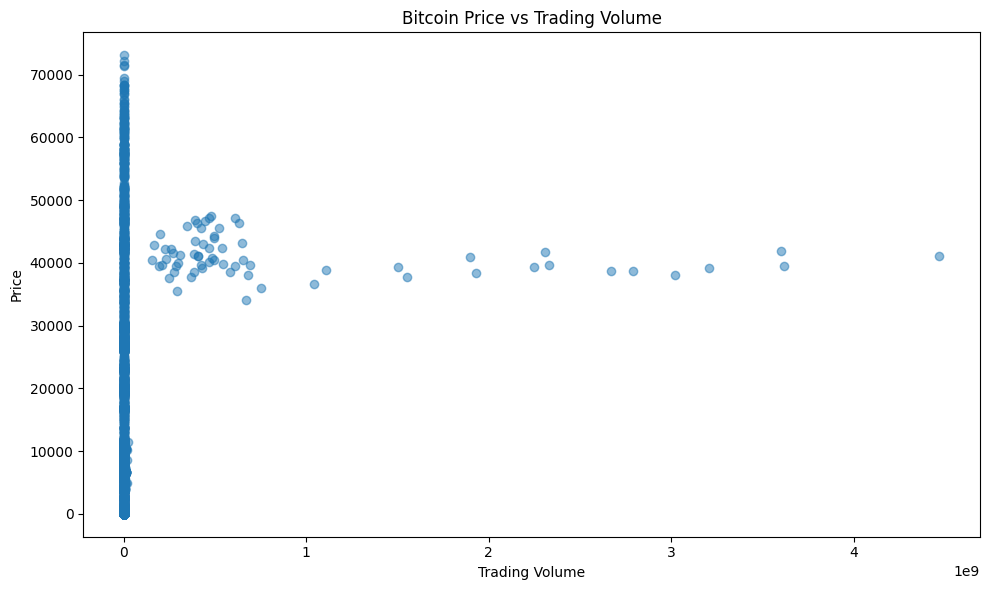

In [77]:
plt.figure(figsize=(10, 6))

plt.scatter(df['Vol.'], df['Price'], alpha=0.5)

plt.title('Bitcoin Price vs Trading Volume')
plt.xlabel('Trading Volume')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

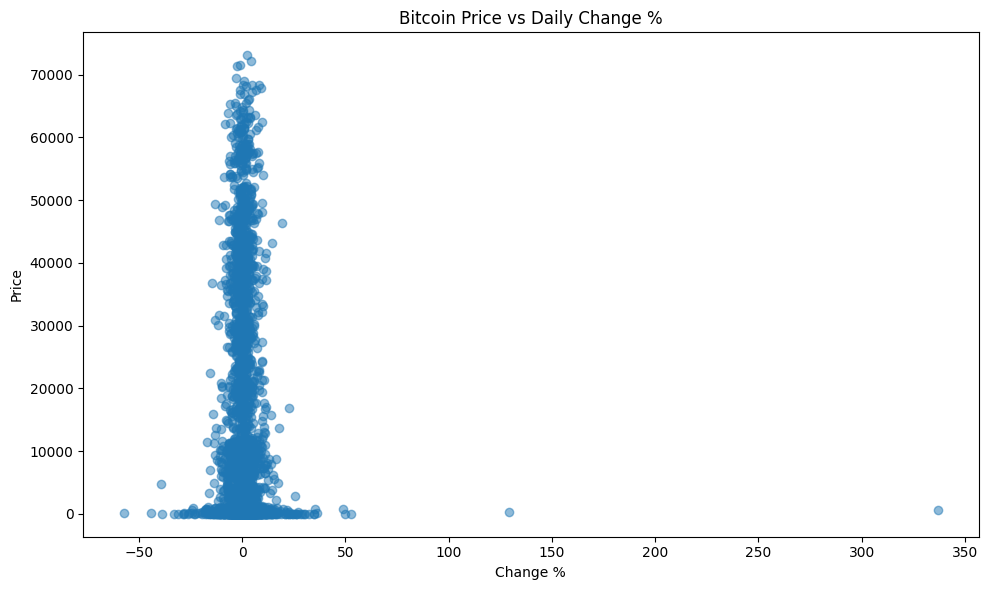

In [78]:
plt.figure(figsize=(10, 6))

plt.scatter(df['Change %'], df['Price'], alpha=0.5)

plt.title('Bitcoin Price vs Daily Change %')
plt.xlabel('Change %')
plt.ylabel('Price')

plt.tight_layout()
plt.show()

In [79]:
df.isnull().sum()

,0
Date,0
Price,0
Open,0
High,0
Low,0
Vol.,0
Change %,0


In [80]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      4999 non-null   datetime64[ns]
 1   Price     4999 non-null   float64       
 2   Open      4999 non-null   float64       
 3   High      4999 non-null   float64       
 4   Low       4999 non-null   float64       
 5   Vol.      4999 non-null   float64       
 6   Change %  4999 non-null   float64       
dtypes: datetime64[ns](1), float64(6)
memory usage: 273.5 KB


In [81]:
# Log-transform Volume

df['Vol_Log'] = np.log1p(df['Vol.'])

print("Vol_Log created successfully")
print("Missing values:", df['Vol_Log'].isna().sum())
print("Min:", df['Vol_Log'].min())
print("Max:", df['Vol_Log'].max())

Vol_Log created successfully
Missing values: 0
Min: 4.394449154672439
Max: 22.220654245795604


In [82]:
# Time-based train-test split (80% train, 20% test)

split_index = int(len(df) * 0.80)

train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("\nTrain period:")
print(train_df['Date'].min(), "to", train_df['Date'].max())

print("\nTest period:")
print(test_df['Date'].min(), "to", test_df['Date'].max())

Train shape: (3999, 8)
Test shape: (1000, 8)

Train period:
2010-07-18 00:00:00 to 2021-06-28 00:00:00

Test period:
2021-06-29 00:00:00 to 2024-03-24 00:00:00


In [83]:
# Feature selection

features = [
    'Price',
    'Open',
    'High',
    'Low',
    'Vol_Log',
    'Change %'
]

target = 'Price'

X_train = train_df[features]
X_test = test_df[features]

y_train = train_df[target]
y_test = test_df[target]

print("Features:", features)
print("Target:", target)

print("\nX_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Features: ['Price', 'Open', 'High', 'Low', 'Vol_Log', 'Change %']
Target: Price

X_train shape: (3999, 6)
X_test shape: (1000, 6)
y_train shape: (3999,)
y_test shape: (1000,)


In [84]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

print("\nTraining scaled range:")
print("Min:", X_train_scaled.min(axis=0))
print("Max:", X_train_scaled.max(axis=0))

print("\nTesting scaled range:")
print("Min:", X_test_scaled.min(axis=0))
print("Max:", X_test_scaled.max(axis=0))

X_train_scaled shape: (3999, 6)
X_test_scaled shape: (1000, 6)

Training scaled range:
Min: [0. 0. 0. 0. 0. 0.]
Max: [1. 1. 1. 1. 1. 1.]

Testing scaled range:
Min: [0.24828299 0.24827758 0.25123538 0.24979579 0.09413504 0.1055196 ]
Max: [1.14990998 1.14985632 1.13836355 1.14936803 1.43416099 0.18221038]


In [85]:
# Separate scaled target variable

y_train_scaled = X_train_scaled[:, 0]
y_test_scaled = X_test_scaled[:, 0]

print("y_train_scaled shape:", y_train_scaled.shape)
print("y_test_scaled shape:", y_test_scaled.shape)

print("\nFirst 5 scaled training targets:")
print(y_train_scaled[:5])

print("\nFirst 5 scaled testing targets:")
print(y_test_scaled[:5])

y_train_scaled shape: (3999,)
y_test_scaled shape: (1000,)

First 5 scaled training targets:
[0. 0. 0. 0. 0.]

First 5 scaled testing targets:
[0.56396205 0.55124896 0.52790491 0.532151   0.54677782]


In [86]:
# Create sequences using the previous 60 days

window_size = 60

def create_sequences(data, target, window_size, horizon):
    X_seq = []
    y_seq = []

    for i in range(window_size, len(data) - horizon + 1):
        X_seq.append(data[i - window_size:i])
        y_seq.append(target[i:i + horizon])

    return np.array(X_seq), np.array(y_seq)

print("Window size:", window_size)

Window size: 60


In [87]:
# Create 1-day forecasting sequences

X_train_1d, y_train_1d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    horizon=1
)

print("X_train_1d shape:", X_train_1d.shape)
print("y_train_1d shape:", y_train_1d.shape)

X_train_1d shape: (3939, 60, 6)
y_train_1d shape: (3939, 1)


In [88]:
# Chronological validation split

val_index = int(len(X_train_1d) * 0.90)

X_train_final = X_train_1d[:val_index]
y_train_final = y_train_1d[:val_index]

X_val = X_train_1d[val_index:]
y_val = y_train_1d[val_index:]

print("Final training shapes:")
print("X_train_final:", X_train_final.shape)
print("y_train_final:", y_train_final.shape)

print("\nValidation shapes:")
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

Final training shapes:
X_train_final: (3545, 60, 6)
y_train_final: (3545, 1)

Validation shapes:
X_val: (394, 60, 6)
y_val: (394, 1)


In [89]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense

cnn_1d = Sequential([
    Input(shape=(60, 6)),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation='relu'
    ),

    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(64, activation='relu'),

    Dense(1)
])

cnn_1d.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 58, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 29, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1856)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       118,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,129 (469.25 KB)

 Trainable params: 120,129 (469.25 KB)

 Non-trainable params: 0 (0.00 B)

In [90]:
# Compile CNN model

cnn_1d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("CNN compiled successfully.")

CNN compiled successfully.


In [91]:
history_cnn_1d = cnn_1d.fit(
    X_train_final,
    y_train_final,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0067 - mae: 0.0482 - val_loss: 0.4223 - val_mae: 0.5155
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0028 - mae: 0.0333 - val_loss: 0.1423 - val_mae: 0.2860
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0025 - mae: 0.0322 - val_loss: 0.2473 - val_mae: 0.3557
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 6.6272e-04 - mae: 0.0177 - val_loss: 0.1243 - val_mae: 0.2676
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 5.6757e-04 - mae: 0.0148 - val_loss: 0.0050 - val_mae: 0.0512
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.6618e-04 - mae: 0.0137 - val_loss: 0.1136 - val_mae: 0.2438
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.0668e-04 - mae: 0.0132 - val_loss: 0.0176 - val_mae: 0.0972
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 2.4800e-04 - mae: 0.0101 - val_loss: 0.1671 - val_mae: 0.2946
Epoch 9/20
111/111 ━━━━━━━━━━━━━━━━━

In [92]:
# Create test sequences with the last 60 training days as context

test_context_X = np.concatenate(
    [X_train_scaled[-window_size:], X_test_scaled],
    axis=0
)

test_context_y = np.concatenate(
    [y_train_scaled[-window_size:], y_test_scaled],
    axis=0
)

X_test_1d, y_test_1d = create_sequences(
    test_context_X,
    test_context_y,
    window_size,
    horizon=1
)

print("X_test_1d shape:", X_test_1d.shape)
print("y_test_1d shape:", y_test_1d.shape)

X_test_1d shape: (1000, 60, 6)
y_test_1d shape: (1000, 1)


In [93]:
# Predict next-day prices on the unseen test data

y_pred_1d_scaled = cnn_1d.predict(X_test_1d)

print("Prediction shape:", y_pred_1d_scaled.shape)

print("\nFirst 5 scaled predictions:")
print(y_pred_1d_scaled[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Prediction shape: (1000, 1)

First 5 scaled predictions:
[[0.37388885]
 [0.37417132]
 [0.3788486 ]
 [0.38279092]
 [0.38690203]]


In [94]:
print("Scaled prediction range:")
print("Min:", y_pred_1d_scaled.min())
print("Max:", y_pred_1d_scaled.max())

print("\nPredictions above 1:", (y_pred_1d_scaled > 1).sum())
print("Predictions below 0:", (y_pred_1d_scaled < 0).sum())

Scaled prediction range:
Min: 0.2141137
Max: 0.87831527

Predictions above 1: 0
Predictions below 0: 0


In [95]:
# Convert scaled predictions back to actual Price values

y_pred_1d = scaler.inverse_transform(
    np.column_stack([
        y_pred_1d_scaled.ravel(),
        np.zeros((len(y_pred_1d_scaled), 5))
    ])
)[:, 0]

y_actual_1d = scaler.inverse_transform(
    np.column_stack([
        y_test_1d.ravel(),
        np.zeros((len(y_test_1d), 5))
    ])
)[:, 0]

print("Actual price range:")
print("Min:", y_actual_1d.min())
print("Max:", y_actual_1d.max())

print("\nPredicted price range:")
print("Min:", y_pred_1d.min())
print("Max:", y_pred_1d.max())

print("\nFirst 5 actual prices:")
print(y_actual_1d[:5])

print("\nFirst 5 predicted prices:")
print(y_pred_1d[:5])

Actual price range:
Min: 15776.2
Max: 73066.3

Predicted price range:
Min: 13605.055624365808
Max: 55808.95490465165

First 5 actual prices:
[35834.7 35026.9 33543.6 33813.4 34742.8]

First 5 predicted prices:
[23757.29665356 23775.24479532 24072.44390497 24322.94148769
 24584.16477995]


In [96]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(y_actual_1d, y_pred_1d)

rmse = np.sqrt(
    mean_squared_error(y_actual_1d, y_pred_1d)
)

mape = np.mean(
    np.abs((y_actual_1d - y_pred_1d) / y_actual_1d)
) * 100

print("CNN 1-Day Forecast Metrics")
print("---------------------------")
print("MAE :", mae)
print("RMSE:", rmse)
print("MAPE:", mape, "%")

CNN 1-Day Forecast Metrics
---------------------------
MAE : 7839.084867828222
RMSE: 9015.366730698457
MAPE: 21.84799896280237 %


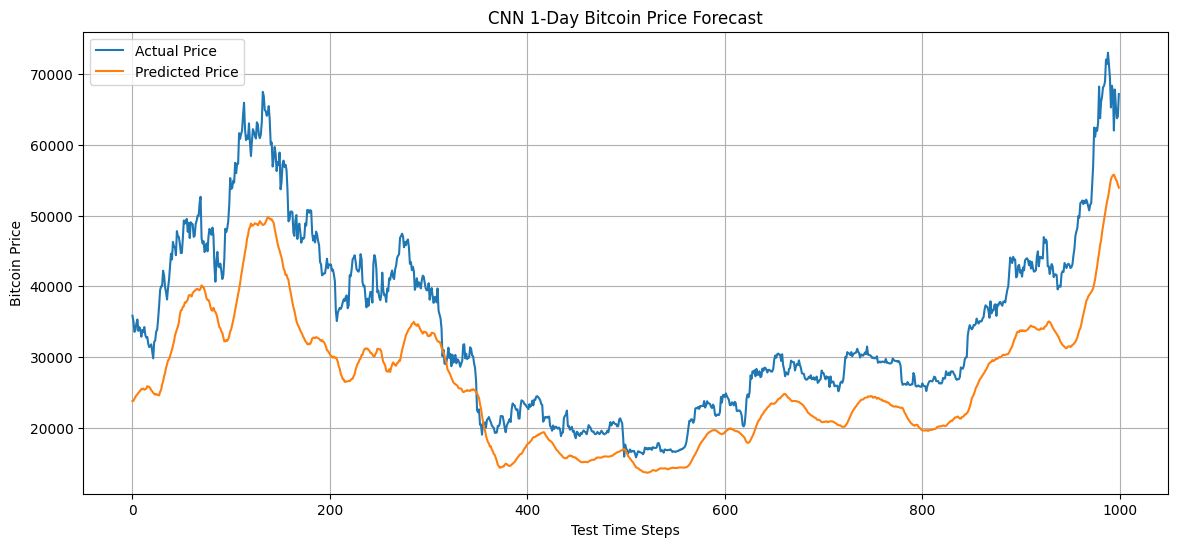

In [97]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    y_actual_1d,
    label='Actual Price'
)

plt.plot(
    y_pred_1d,
    label='Predicted Price'
)

plt.title('CNN 1-Day Bitcoin Price Forecast')
plt.xlabel('Test Time Steps')
plt.ylabel('Bitcoin Price')
plt.legend()
plt.grid(True)

plt.show()

In [98]:
cnn_1d_results = {
    'Model': '1D-CNN',
    'Horizon': '1-Day',
    'MAE': mae,
    'RMSE': rmse,
    'MAPE': mape
}

print(cnn_1d_results)

{'Model': '1D-CNN', 'Horizon': '1-Day', 'MAE': 7839.084867828222, 'RMSE': np.float64(9015.366730698457), 'MAPE': np.float64(21.84799896280237)}


In [99]:
# Create 3-day forecasting sequences

X_train_3d, y_train_3d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    horizon=3
)

print("X_train_3d shape:", X_train_3d.shape)
print("y_train_3d shape:", y_train_3d.shape)

X_train_3d shape: (3937, 60, 6)
y_train_3d shape: (3937, 3)


In [100]:
# Chronological validation split for 3-day forecasting

val_index_3d = int(len(X_train_3d) * 0.90)

X_train_final_3d = X_train_3d[:val_index_3d]
y_train_final_3d = y_train_3d[:val_index_3d]

X_val_3d = X_train_3d[val_index_3d:]
y_val_3d = y_train_3d[val_index_3d:]

print("Final training shapes:")
print("X_train_final_3d:", X_train_final_3d.shape)
print("y_train_final_3d:", y_train_final_3d.shape)

print("\nValidation shapes:")
print("X_val_3d:", X_val_3d.shape)
print("y_val_3d:", y_val_3d.shape)

Final training shapes:
X_train_final_3d: (3543, 60, 6)
y_train_final_3d: (3543, 3)

Validation shapes:
X_val_3d: (394, 60, 6)
y_val_3d: (394, 3)


In [101]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense

cnn_3d = Sequential([
    Input(shape=(60, 6)),

    Conv1D(
        filters=64,
        kernel_size=3,
        activation='relu'
    ),

    MaxPooling1D(pool_size=2),

    Flatten(),

    Dense(64, activation='relu'),

    Dense(3)
])

cnn_3d.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_1 (Conv1D)               │ (None, 58, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 29, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1856)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       118,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,259 (469.76 KB)

 Trainable params: 120,259 (469.76 KB)

 Non-trainable params: 0 (0.00 B)

In [102]:
# Compile 3-Day CNN

cnn_3d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("3-Day CNN compiled successfully.")

3-Day CNN compiled successfully.


In [103]:
history_cnn_3d = cnn_3d.fit(
    X_train_final_3d,
    y_train_final_3d,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_3d, y_val_3d),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0026 - mae: 0.0306 - val_loss: 0.2524 - val_mae: 0.3791
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0019 - mae: 0.0274 - val_loss: 0.0670 - val_mae: 0.1894
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0015 - mae: 0.0218 - val_loss: 0.0367 - val_mae: 0.1263
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 6.9439e-04 - mae: 0.0168 - val_loss: 0.0275 - val_mae: 0.0982
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 3.7221e-04 - mae: 0.0114 - val_loss: 0.0324 - val_mae: 0.1189
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 4.9629e-04 - mae: 0.0133 - val_loss: 0.0142 - val_mae: 0.0781
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 2.9837e-04 - mae: 0.0106 - val_loss: 0.0177 - val_mae: 0.0938
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 2.9618e-04 - mae: 0.0103 - val_loss: 0.0126 - val_mae: 0.0780
Epoch 9/20
111/111 ━━━━━━━━━━━━━

In [104]:
# Create test sequences for 3-day forecasting

X_test_3d, y_test_3d = create_sequences(
    test_context_X,
    test_context_y,
    window_size,
    horizon=3
)

print("X_test_3d shape:", X_test_3d.shape)
print("y_test_3d shape:", y_test_3d.shape)

X_test_3d shape: (998, 60, 6)
y_test_3d shape: (998, 3)


In [105]:
# Generate 3-day predictions

y_pred_3d_scaled = cnn_3d.predict(X_test_3d)

print("Prediction shape:", y_pred_3d_scaled.shape)

print("\nFirst 5 predictions:")
print(y_pred_3d_scaled[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Prediction shape: (998, 3)

First 5 predictions:
[[0.4786769  0.5101438  0.538247  ]
 [0.48338905 0.51047117 0.5347992 ]
 [0.48370144 0.5099805  0.53278244]
 [0.48177665 0.51311445 0.53094524]
 [0.47766718 0.5114752  0.5302819 ]]


In [106]:
print("3-Day scaled prediction range:")
print("Min:", y_pred_3d_scaled.min())
print("Max:", y_pred_3d_scaled.max())

print("\nPredictions above 1:", (y_pred_3d_scaled > 1).sum())
print("Predictions below 0:", (y_pred_3d_scaled < 0).sum())

3-Day scaled prediction range:
Min: 0.23516773
Max: 1.1558045

Predictions above 1: 94
Predictions below 0: 0


In [107]:
# Convert 3-day predictions back to actual Bitcoin prices

predictions_3d = []
actuals_3d = []

for day in range(3):

    pred_day = scaler.inverse_transform(
        np.column_stack([
            y_pred_3d_scaled[:, day],
            np.zeros((len(y_pred_3d_scaled), 5))
        ])
    )[:, 0]

    actual_day = scaler.inverse_transform(
        np.column_stack([
            y_test_3d[:, day],
            np.zeros((len(y_test_3d), 5))
        ])
    )[:, 0]

    predictions_3d.append(pred_day)
    actuals_3d.append(actual_day)

predictions_3d = np.array(predictions_3d).T
actuals_3d = np.array(actuals_3d).T

print("Predictions shape:", predictions_3d.shape)
print("Actuals shape:", actuals_3d.shape)

print("\nFirst 5 predicted rows:")
print(predictions_3d[:5])

print("\nFirst 5 actual rows:")
print(actuals_3d[:5])

Predictions shape: (998, 3)
Actuals shape: (998, 3)

First 5 predicted rows:
[[30415.61223769 32415.04621363 34200.74429455]
 [30715.02693353 32435.84621248 33981.67016239]
 [30734.87631335 32404.66893816 33853.52217236]
 [30612.57406225 32603.80279465 33736.78539801]
 [30351.45492148 32499.64373264 33694.63623791]]

First 5 actual rows:
[[35834.7 35026.9 33543.6]
 [35026.9 33543.6 33813.4]
 [33543.6 33813.4 34742.8]
 [33813.4 34742.8 35298.2]
 [34742.8 35298.2 33687.8]]


In [108]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

print("CNN 3-Day Forecast Metrics")
print("---------------------------")

for day in range(3):

    mae_day = mean_absolute_error(
        actuals_3d[:, day],
        predictions_3d[:, day]
    )

    rmse_day = np.sqrt(
        mean_squared_error(
            actuals_3d[:, day],
            predictions_3d[:, day]
        )
    )

    mape_day = np.mean(
        np.abs(
            (actuals_3d[:, day] - predictions_3d[:, day])
            / actuals_3d[:, day]
        )
    ) * 100

    print(f"\nDay {day + 1}:")
    print(f"MAE : {mae_day:.2f}")
    print(f"RMSE: {rmse_day:.2f}")
    print(f"MAPE: {mape_day:.2f}%")

CNN 3-Day Forecast Metrics
---------------------------

Day 1:
MAE : 2325.29
RMSE: 3255.60
MAPE: 6.54%

Day 2:
MAE : 2345.26
RMSE: 3108.49
MAPE: 6.82%

Day 3:
MAE : 3346.21
RMSE: 4300.28
MAPE: 9.91%


In [109]:
# Overall 3-Day metrics across all forecast horizons

actual_flat = actuals_3d.flatten()
pred_flat = predictions_3d.flatten()

mae_3d = mean_absolute_error(actual_flat, pred_flat)

rmse_3d = np.sqrt(
    mean_squared_error(actual_flat, pred_flat)
)

mape_3d = np.mean(
    np.abs((actual_flat - pred_flat) / actual_flat)
) * 100

print("CNN 3-Day Overall Metrics")
print("-------------------------")
print("MAE :", mae_3d)
print("RMSE:", rmse_3d)
print("MAPE:", mape_3d, "%")

CNN 3-Day Overall Metrics
-------------------------
MAE : 2672.254639172999
RMSE: 3594.1649475873423
MAPE: 7.755981702206938 %


In [110]:
cnn_3d_results = {
    'Model': '1D-CNN',
    'Horizon': '3-Day',
    'MAE': mae_3d,
    'RMSE': rmse_3d,
    'MAPE': mape_3d
}

print(cnn_3d_results)

{'Model': '1D-CNN', 'Horizon': '3-Day', 'MAE': 2672.254639172999, 'RMSE': np.float64(3594.1649475873423), 'MAPE': np.float64(7.755981702206938)}


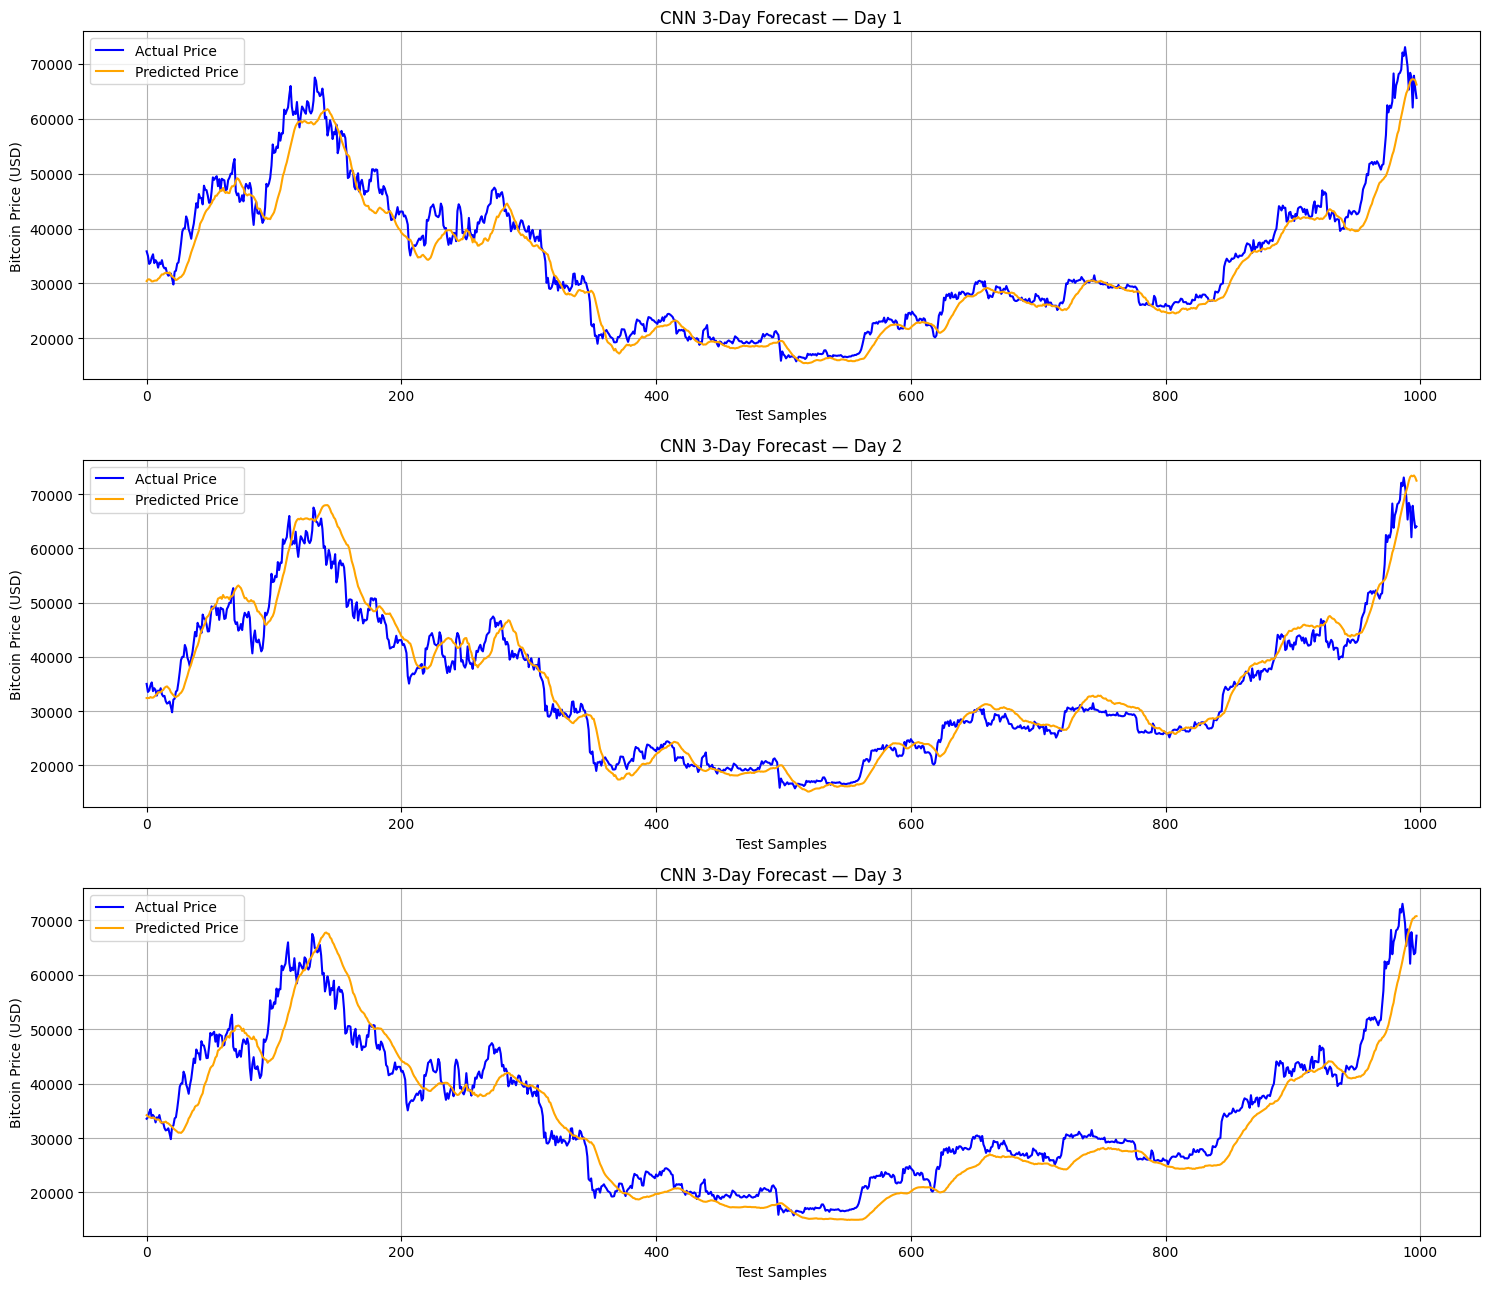

In [111]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(15, 13))

for day in range(3):
    axes[day].plot(
        actuals_3d[:, day],
        label='Actual Price',
        color='blue'
    )

    axes[day].plot(
        predictions_3d[:, day],
        label='Predicted Price',
        color='orange'
    )

    axes[day].set_title(
        f'CNN 3-Day Forecast — Day {day + 1}'
    )
    axes[day].set_xlabel('Test Samples')
    axes[day].set_ylabel('Bitcoin Price (USD)')
    axes[day].legend()
    axes[day].grid(True)

plt.tight_layout()
plt.show()

In [112]:
# Create 7-day forecasting sequences

X_train_7d, y_train_7d = create_sequences(
    X_train_scaled,
    y_train_scaled,
    window_size,
    horizon=7
)

print("X_train_7d shape:", X_train_7d.shape)
print("y_train_7d shape:", y_train_7d.shape)

X_train_7d shape: (3933, 60, 6)
y_train_7d shape: (3933, 7)


In [113]:
# Chronological 90/10 validation split

val_index_7d = int(len(X_train_7d) * 0.90)

X_train_final_7d = X_train_7d[:val_index_7d]
y_train_final_7d = y_train_7d[:val_index_7d]

X_val_7d = X_train_7d[val_index_7d:]
y_val_7d = y_train_7d[val_index_7d:]

print("Training:", X_train_final_7d.shape, y_train_final_7d.shape)
print("Validation:", X_val_7d.shape, y_val_7d.shape)

Training: (3539, 60, 6) (3539, 7)
Validation: (394, 60, 6) (394, 7)


In [114]:
cnn_7d = Sequential([
    Input(shape=(60, 6)),
    Conv1D(filters=64, kernel_size=3, activation='relu'),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(7)
])

cnn_7d.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_2 (Conv1D)               │ (None, 58, 64)         │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 29, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1856)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │       118,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,519 (470.78 KB)

 Trainable params: 120,519 (470.78 KB)

 Non-trainable params: 0 (0.00 B)

In [115]:
cnn_7d.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

print("7-Day CNN compiled successfully.")

7-Day CNN compiled successfully.


In [116]:
history_cnn_7d = cnn_7d.fit(
    X_train_final_7d,
    y_train_final_7d,
    epochs=20,
    batch_size=32,
    validation_data=(X_val_7d, y_val_7d),
    shuffle=False
)

Epoch 1/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.0017 - mae: 0.0227 - val_loss: 0.0317 - val_mae: 0.1265
Epoch 2/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0012 - mae: 0.0201 - val_loss: 0.0536 - val_mae: 0.1331
Epoch 3/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 7.9578e-04 - mae: 0.0184 - val_loss: 0.0311 - val_mae: 0.1129
Epoch 4/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 6.7626e-04 - mae: 0.0167 - val_loss: 0.0184 - val_mae: 0.0874
Epoch 5/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 7.9045e-04 - mae: 0.0159 - val_loss: 0.0196 - val_mae: 0.0940
Epoch 6/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 6.2054e-04 - mae: 0.0162 - val_loss: 0.0195 - val_mae: 0.0907
Epoch 7/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 3.7241e-04 - mae: 0.0123 - val_loss: 0.0158 - val_mae: 0.0830
Epoch 8/20
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 2.6968e-04 - mae: 0.0097 - val_loss: 0.0142 - val_mae: 0.0784
Epoch 9/20
111/111 ━━━━━━━━━━━

In [117]:
X_test_7d, y_test_7d = create_sequences(
    test_context_X,
    test_context_y,
    window_size,
    horizon=7
)

print("X_test_7d shape:", X_test_7d.shape)
print("y_test_7d shape:", y_test_7d.shape)

X_test_7d shape: (994, 60, 6)
y_test_7d shape: (994, 7)


In [118]:
y_pred_7d_scaled = cnn_7d.predict(X_test_7d)

print("Prediction shape:", y_pred_7d_scaled.shape)
print("First 5 predictions (scaled):")
print(y_pred_7d_scaled[:5])

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Prediction shape: (994, 7)
First 5 predictions (scaled):
[[0.58784795 0.61195797 0.4719865  0.5762965  0.47579637 0.5856212
  0.51333904]
 [0.58366233 0.6062297  0.4752435  0.57217276 0.4785384  0.58085364
  0.51688033]
 [0.5889512  0.613376   0.48110688 0.5766654  0.48818195 0.5877006
  0.51854676]
 [0.59013647 0.61420435 0.48635983 0.57733554 0.49372554 0.58855236
  0.52636963]
 [0.5890548  0.6119798  0.48820677 0.57654226 0.49443087 0.58686864
  0.5286121 ]]


In [119]:
predictions_7d = []
actuals_7d = []

for day in range(7):

    pred_day = scaler.inverse_transform(
        np.column_stack([
            y_pred_7d_scaled[:, day],
            np.zeros((len(y_pred_7d_scaled), 5))
        ])
    )[:, 0]

    actual_day = scaler.inverse_transform(
        np.column_stack([
            y_test_7d[:, day],
            np.zeros((len(y_test_7d), 5))
        ])
    )[:, 0]

    predictions_7d.append(pred_day)
    actuals_7d.append(actual_day)

predictions_7d = np.array(predictions_7d).T
actuals_7d = np.array(actuals_7d).T

print("Predictions shape:", predictions_7d.shape)
print("Actuals shape:", actuals_7d.shape)

print("\nFirst 5 predicted prices:")
print(predictions_7d[:5])

print("\nFirst 5 actual prices:")
print(actuals_7d[:5])

Predictions shape: (994, 7)
Actuals shape: (994, 7)

First 5 predicted prices:
[[37352.428899   38884.39880743 29990.49995227 36618.44117537
  30232.58209481 37210.9381566  32618.07344208]
 [37086.47144823 38520.42155142 30197.45274496 36356.41496983
  30406.81238384 36908.00503416 32843.08989   ]
 [37422.52853098 38974.50309963 30570.01587086 36641.88094101
  31019.57156353 37343.06662712 32948.97597303]
 [37497.84331198 39027.13558035 30903.79298286 36684.46185637
  31371.81568108 37397.18752728 33446.0474679 ]
 [37429.11469231 38885.78496904 31021.14898515 36634.05632381
  31416.63301291 37290.20311947 33588.53427725]]

First 5 actual prices:
[[35834.7 35026.9 33543.6 33813.4 34742.8 35298.2 33687.8]
 [35026.9 33543.6 33813.4 34742.8 35298.2 33687.8 34225.6]
 [33543.6 33813.4 34742.8 35298.2 33687.8 34225.6 33867.8]
 [33813.4 34742.8 35298.2 33687.8 34225.6 33867.8 32866.3]
 [34742.8 35298.2 33687.8 34225.6 33867.8 32866.3 33797.4]]


In [120]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

for day in range(7):

    mae_day = mean_absolute_error(
        actuals_7d[:, day],
        predictions_7d[:, day]
    )

    rmse_day = np.sqrt(
        mean_squared_error(
            actuals_7d[:, day],
            predictions_7d[:, day]
        )
    )

    mape_day = np.mean(
        np.abs(
            (actuals_7d[:, day] - predictions_7d[:, day])
            / actuals_7d[:, day]
        )
    ) * 100

    print(
        f"Day {day + 1}: "
        f"MAE = {mae_day:.2f}, "
        f"RMSE = {rmse_day:.2f}, "
        f"MAPE = {mape_day:.2f}%"
    )

Day 1: MAE = 5144.92, RMSE = 7148.58, MAPE = 13.38%
Day 2: MAE = 5799.49, RMSE = 8120.82, MAPE = 15.08%
Day 3: MAE = 2382.70, RMSE = 3313.73, MAPE = 6.80%
Day 4: MAE = 4967.69, RMSE = 7040.01, MAPE = 13.30%
Day 5: MAE = 2818.95, RMSE = 3942.16, MAPE = 8.05%
Day 6: MAE = 5069.29, RMSE = 7259.88, MAPE = 13.73%
Day 7: MAE = 3082.35, RMSE = 4161.93, MAPE = 8.89%


In [121]:
actual_flat_7d = actuals_7d.flatten()
pred_flat_7d = predictions_7d.flatten()

mae_7d = mean_absolute_error(
    actual_flat_7d,
    pred_flat_7d
)

rmse_7d = np.sqrt(
    mean_squared_error(
        actual_flat_7d,
        pred_flat_7d
    )
)

mape_7d = np.mean(
    np.abs(
        (actual_flat_7d - pred_flat_7d)
        / actual_flat_7d
    )
) * 100

print("CNN 7-Day Overall Metrics")
print("-------------------------")
print(f"MAE : {mae_7d:.2f}")
print(f"RMSE: {rmse_7d:.2f}")
print(f"MAPE: {mape_7d:.2f}%")

CNN 7-Day Overall Metrics
-------------------------
MAE : 4180.77
RMSE: 6131.43
MAPE: 11.32%


In [122]:
cnn_7d_results = {
    'Model': '1D-CNN',
    'Horizon': '7-Day',
    'MAE': mae_7d,
    'RMSE': rmse_7d,
    'MAPE': mape_7d
}

print(cnn_7d_results)

{'Model': '1D-CNN', 'Horizon': '7-Day', 'MAE': 4180.768364235476, 'RMSE': np.float64(6131.425696567083), 'MAPE': np.float64(11.318410732305201)}


In [123]:
cnn_results = pd.DataFrame([
    cnn_1d_results,
    cnn_3d_results,
    cnn_7d_results
])

cnn_results

,Model,Horizon,MAE,RMSE,MAPE
0,1D-CNN,1-Day,7839.084868,9015.366731,21.847999
1,1D-CNN,3-Day,2672.254639,3594.164948,7.755982
2,1D-CNN,7-Day,4180.768364,6131.425697,11.318411


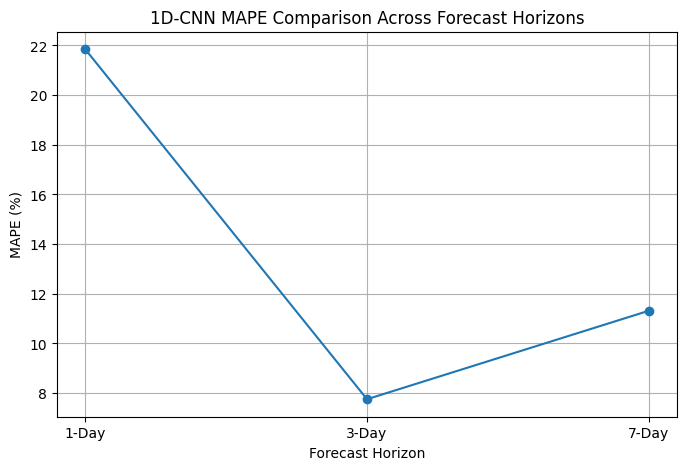

In [124]:
plt.figure(figsize=(8, 5))

plt.plot(
    cnn_results['Horizon'],
    cnn_results['MAPE'],
    marker='o'
)

plt.title('1D-CNN MAPE Comparison Across Forecast Horizons')
plt.xlabel('Forecast Horizon')
plt.ylabel('MAPE (%)')
plt.grid(True)

plt.show()

In [125]:
import os

processed_path = "/content/drive/MyDrive/cryptocast/data/processed"

os.makedirs(processed_path, exist_ok=True)

cleaned_file = os.path.join(
    processed_path,
    "bitcoin_cleaned.csv"
)

df.to_csv(cleaned_file, index=False)

print("Cleaned dataset saved successfully!")
print(cleaned_file)

Cleaned dataset saved successfully!
/content/drive/MyDrive/cryptocast/data/processed/bitcoin_cleaned.csv


In [126]:
import os

processed_path = "/content/drive/MyDrive/cryptocast/data/processed"

print(os.listdir(processed_path))

['bitcoin_cleaned.csv']


In [127]:
cnn_results_path = "/content/drive/MyDrive/cryptocast/results/cnn_results.csv"

cnn_results.to_csv(
    cnn_results_path,
    index=False
)

print("CNN results saved successfully!")
print(cnn_results_path)

CNN results saved successfully!
/content/drive/MyDrive/cryptocast/results/cnn_results.csv


In [128]:
print("CNN 1D:", cnn_1d.output_shape)
print("CNN 3D:", cnn_3d.output_shape)
print("CNN 7D:", cnn_7d.output_shape)

CNN 1D: (None, 1)
CNN 3D: (None, 3)
CNN 7D: (None, 7)


In [132]:
import os

model_dir = "/content/mydrive/MyDrive/cryptocast/streamlit/models"

os.makedirs(model_dir, exist_ok=True)

print("Folder exists:", os.path.exists(model_dir))
print("Folder path:", model_dir)

Folder exists: True
Folder path: /content/mydrive/MyDrive/cryptocast/streamlit/models


In [134]:
import os

model_dir = "/content/mydrive/MyDrive/cryptocast/streamlit/models"

print("Current folder exists:", os.path.exists(model_dir))

if os.path.exists(model_dir):
    print("Files in models folder:")
    for file in os.listdir(model_dir):
        print(file)
else:
    print("Models folder not found")

print("\nChecking Drive mount:")
print("mydrive exists:", os.path.exists("/content/mydrive/MyDrive"))
print("drive exists:", os.path.exists("/content/drive/MyDrive"))

Current folder exists: True
Files in models folder:
cnn_3d.keras
cnn_7d.keras

Checking Drive mount:
mydrive exists: True
drive exists: True


In [135]:
import os

model_dir = "/content/mydrive/MyDrive/cryptocast/streamlit/models"

print("CNN 3D exists:", os.path.exists(os.path.join(model_dir, "cnn_3d.keras")))
print("CNN 7D exists:", os.path.exists(os.path.join(model_dir, "cnn_7d.keras")))

print("\nFiles in folder:")
print(os.listdir(model_dir))

CNN 3D exists: True
CNN 7D exists: True

Files in folder:
['cnn_3d.keras', 'cnn_7d.keras']


In [136]:
import os

model_dir = "/content/mydrive/MyDrive/cryptocast/streamlit/models"

for filename in ["cnn_3d.keras", "cnn_7d.keras"]:
    path = os.path.join(model_dir, filename)
    print(filename, "Size:", round(os.path.getsize(path) / 1024, 2), "KB")

cnn_3d.keras Size: 1438.64 KB
cnn_7d.keras Size: 1441.69 KB


In [137]:
import os

print("mydrive:", os.path.exists("/content/mydrive/MyDrive"))
print("drive:", os.path.exists("/content/drive/MyDrive"))

mydrive: True
drive: True


In [138]:
import os

for path in [
    "/content/mydrive/MyDrive/cryptocast/streamlit/models",
    "/content/drive/MyDrive/cryptocast/streamlit/models"
]:
    print(f"\nPath: {path}")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        print("Files:", os.listdir(path))


Path: /content/mydrive/MyDrive/cryptocast/streamlit/models
Exists: True
Files: ['cnn_3d.keras', 'cnn_7d.keras']

Path: /content/drive/MyDrive/cryptocast/streamlit/models
Exists: True
Files: ['transformer_1d.keras', 'transformer_3d.keras', 'transformer_7d.keras', 'scaler_1d.pkl', 'scaler_3d.pkl', 'scaler_7d.pkl', 'cnn_1d.keras', 'cnn_scaler.pkl']


In [139]:
from google.colab import drive
drive.mount('/content/drive')

import os

model_dir = "/content/drive/MyDrive/cryptocast/streamlit/models"
os.makedirs(model_dir, exist_ok=True)

cnn_3d.save(os.path.join(model_dir, "cnn_3d.keras"))
cnn_7d.save(os.path.join(model_dir, "cnn_7d.keras"))

print("Saved files:")
print(os.listdir(model_dir))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saved files:
['transformer_1d.keras', 'transformer_3d.keras', 'transformer_7d.keras', 'scaler_1d.pkl', 'scaler_3d.pkl', 'scaler_7d.pkl', 'cnn_1d.keras', 'cnn_scaler.pkl', 'cnn_3d.keras', 'cnn_7d.keras']


In [140]:
import os
import joblib

model_dir = "/content/drive/MyDrive/cryptocast/streamlit/models"
os.makedirs(model_dir, exist_ok=True)

joblib.dump(scaler, os.path.join(model_dir, "cnn_scaler_3d.pkl"))
joblib.dump(scaler, os.path.join(model_dir, "cnn_scaler_7d.pkl"))

print("Saved:")
print("cnn_scaler_3d.pkl")
print("cnn_scaler_7d.pkl")

Saved:
cnn_scaler_3d.pkl
cnn_scaler_7d.pkl
